# Assignment 2
## Statement of AI use :
AI was used by the group to as in the previous assignement, to get clearer plottings when the result was not shown good enough. For example when the plot was out of scope or did not looks as intended. Also to trouble shoot python syntax errors when the fix was not obvious. 

## Task 1a

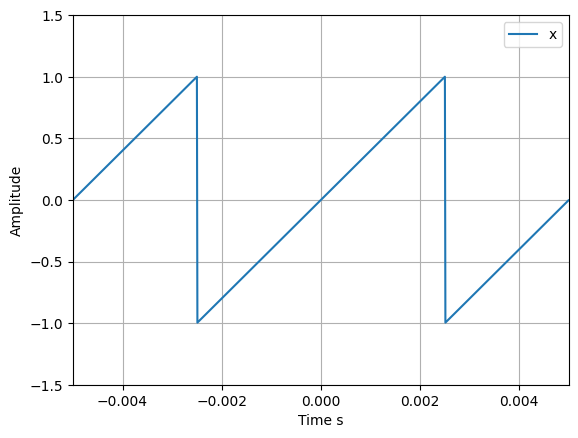

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

dt = 0.00001
t = np.arange(-0.005, 0.005, dt)

x = -1+(1/0.0025)*np.mod(t-0.0025, 0.005)

fig, ax = plt.subplots()

ax.plot(t, x, label='x')
ax.set_xlabel('Time s')
ax.set_ylabel('Amplitude')
ax.set_xlim(-0.005, 0.005)
ax.set_ylim(-1.5 , 1.5)

ax.legend()
ax.grid()

plt.show()

## Task 1b

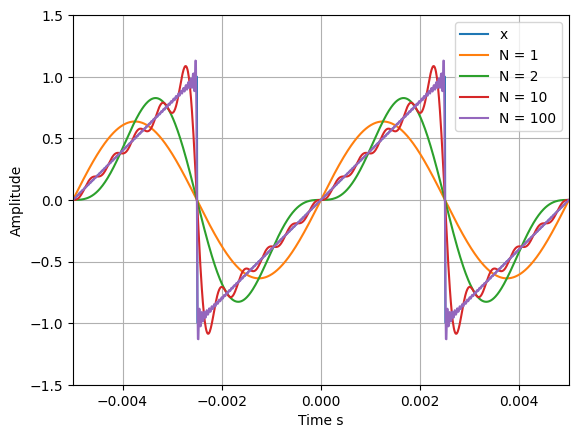

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

dt = 0.00001
t = np.arange(-0.005, 0.005, dt)
x = -1+(1/0.0025)*np.mod(t-0.0025, 0.005)

fig, ax = plt.subplots()
ax.plot(t, x, label='x')

N_val = [1, 2, 10, 100]
w = (2*np.pi) / 0.005

for N in N_val:
    n = np.arange(-N, N + 1)
    fs = 0

    for i in n:
        if i==0:
            cn = 0
        else:
            cn = ((-1.0)**i)*1j*(1/(i*np.pi))

        fs += (cn*np.exp(1j*i*w*t))
        
    if np.max(np.abs(np.imag(fs))) < 1e-12:
        fs = np.real(fs)
    ax.plot(t, fs, label=f'N = {N}')



ax.set_xlabel('Time s')
ax.set_ylabel('Amplitude')
ax.set_xlim(-0.005, 0.005)
ax.set_ylim(-1.5 , 1.5)

ax.legend()
ax.grid()

plt.show()

With this graph, we can observe that the larger the values of $N$ are, the closer the approximation gets to the true signal x(t). When including more components N, higher frequencies will be included and the approximation will become more detailed and sharper at the edges. This also shows how lower frequencies gives smoother and wider looking plots, while higher frequensies gives tighter and sharper graphs.

## Task 1c

The signal is, as stated in the assignment, a periodic signal. That can be seen in the graph because the pattern repeats identically over time. By looking at the fourier transform table we can therefore see that the "T0-periodic" is the one we want to use:

$X(\omega ) = 2\pi\sum_{n} c_n \delta(\omega - n\omega_0)$

After applying the coefficients from the previous task, we get the new expression:

$X(\omega ) = 2\pi\sum_{n=-\infty}^{\infty} \left( (-1)^n j \frac{1}{n\pi} \right) \delta(\omega - n\omega_0)$   for n ≠ 0

/var/folders/19/k6h_ynnd2gqbcfhgqplml5hw0000gn/T/ipykernel_37622/733640203.py:9: RuntimeWarning: divide by zero encountered in divide
  Xn = 2 * np.pi * ((-1.0)**n) * 1j * (1 /(n * np.pi))
/var/folders/19/k6h_ynnd2gqbcfhgqplml5hw0000gn/T/ipykernel_37622/733640203.py:9: RuntimeWarning: invalid value encountered in multiply
  Xn = 2 * np.pi * ((-1.0)**n) * 1j * (1 /(n * np.pi))


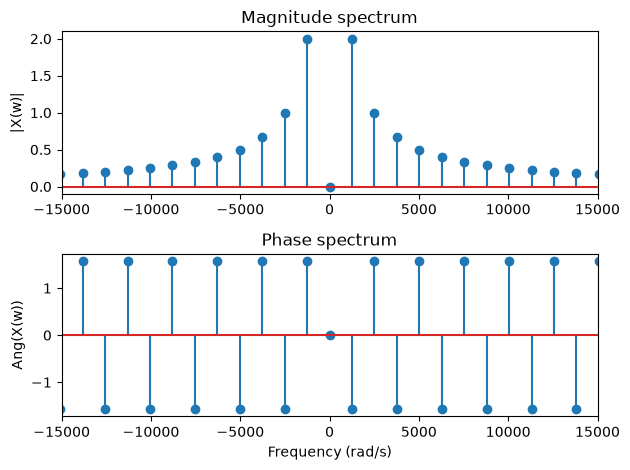

In [24]:
import numpy as np
import matplotlib.pyplot as plt

M = 100
n = np.arange( -M, M + 1, 1)
w = (2*np.pi)/0.005

wn = n * w
Xn = 2 * np.pi * ((-1.0)**n) * 1j * (1 /(n * np.pi)) 
Xn[n == 0] = 0

fig, ax = plt.subplots(2, 1)
# Plot magnitude spectrum
ax[0].stem(wn, np.abs(Xn))
ax[0].set_xlim([-15e3, 15e3])
ax[0].set_title("Magnitude spectrum")
ax[0].set_ylabel("|X(w)|")

# Plot phase spectrum
ax[1].stem(wn, np.angle(Xn))
ax[1].set_xlim([-15e3, 15e3])
ax[1].set_title("Phase spectrum")
ax[1].set_ylabel("Ang(X(w))")
ax[1].set_xlabel("Frequency (rad/s)")

plt.tight_layout()
plt.show()

From the obtained results of plotting the spectrum of the signal x we can see that the the spectrum consists of discrete spectral lines.  This is bacause the signal is periodic, meaning energy only exists at specific frequencies ($(\omega)$*n= n*$(\omega0)$). Additionally, there is no bar at w = 0, meaning the avarege value (DC component) is zero. 

Looking at the amplitude spectum we can see that low frequencies give the largest magintute and give the signal its main shape. While higher frequencies are smaller, creating the sharp edges of the sawtooth wave. 

Choosing N in Task 1b means choosing how many of these spectral lines to include. More lines (higher N) result in a sharper signal approximation.

## Task 2

The frequency response $H(\omega)$ is the continuous-time Fourier transform of the system's impulse response $h(t) = \alpha^2 t e^{-\alpha t} u(t)$. Using the transform table we could determine that "Real poles" Fourier transform was the one to use. By setting n=2, and accounting for linearity property for ${\alpha^2}$, we obtained the frequency response:  

$$H(\omega) = \frac{\alpha^2}{(\alpha + j\omega)^2}$$

where $\alpha = 1000\pi$.

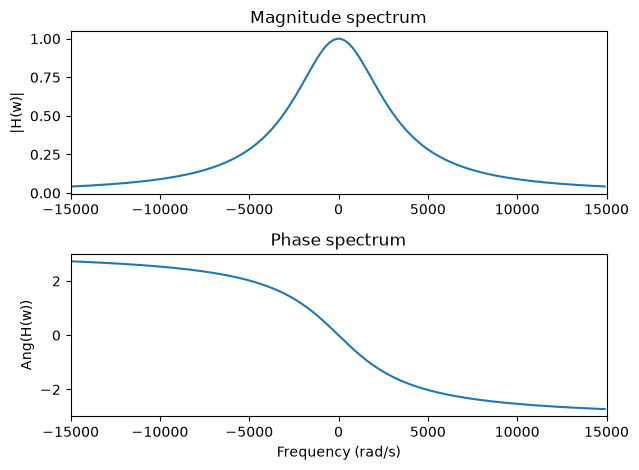

In [23]:
import numpy as np
import matplotlib.pyplot as plt

dw = 100 # stegvärdet

alpha = 1000 * np.pi
w2 = np.arange(-15e3, 15e3, dw)
H = (alpha**2)/((alpha+1j*w2)**2)

fig, ax = plt.subplots(2, 1)
# Plot magnitude spectrum
ax[0].plot(w2, np.abs(H))
ax[0].set_xlim([-15e3, 15e3])
ax[0].set_title("Magnitude spectrum")
ax[0].set_ylabel("|H(w)|")

# Plot phase spectrum
ax[1].plot(w2, np.angle(H))
ax[1].set_xlim([-15e3, 15e3])
ax[1].set_title("Phase spectrum")
ax[1].set_ylabel("Ang(H(w))")
ax[1].set_xlabel("Frequency (rad/s)")

plt.tight_layout()
plt.show()

For the amplitude spectum plot the curve is the highest in the middle where $(\omega)$ = 0 ($\vert{}H(0)\vert{} = 1$) and goes towords zero as the frequency increases. This means that the system works as a low-pass filter, meaning only low frequencies are let through. 

The phase spectrum plot goes downwoards from +$\pi$ for negative frequencies, passes through zero at $\omega$ = 0, and then down towords -$\pi$ for positive frequencies. The conclusion for this is that the system phaseshifts (delays)the frequency components.

## Task 3

/var/folders/19/k6h_ynnd2gqbcfhgqplml5hw0000gn/T/ipykernel_37622/2487989597.py:10: RuntimeWarning: divide by zero encountered in divide
  Xn = 2 * np.pi * ((-1.0)**n) * 1j * (1 /(n * np.pi))
/var/folders/19/k6h_ynnd2gqbcfhgqplml5hw0000gn/T/ipykernel_37622/2487989597.py:10: RuntimeWarning: invalid value encountered in multiply
  Xn = 2 * np.pi * ((-1.0)**n) * 1j * (1 /(n * np.pi))


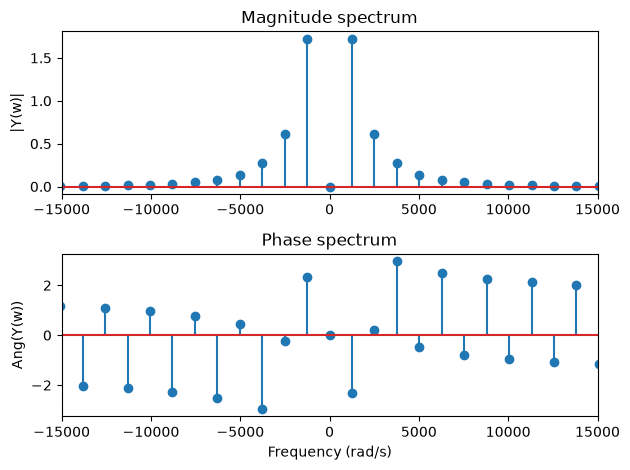

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Input X(w) tranform
M = 100
n = np.arange( -M, M + 1, 1)
w = (2*np.pi)/0.005

wn = n * w
Xn = 2 * np.pi * ((-1.0)**n) * 1j * (1 /(n * np.pi))
Xn[n == 0] = 0

# Frequency response H(w)

alpha = 1000 * np.pi

H = (alpha**2)/((alpha+1j*wn)**2)
Yn = H*Xn

fig, ax = plt.subplots(2, 1)
# Plot magnitude spectrum
ax[0].stem(wn, np.abs(Yn))
ax[0].set_xlim([-15e3, 15e3])
ax[0].set_title("Magnitude spectrum")
ax[0].set_ylabel("|Y(w)|")

# Plot phase spectrum
ax[1].stem(wn, np.angle(Yn))
ax[1].set_xlim([-15e3, 15e3])
ax[1].set_title("Phase spectrum")
ax[1].set_ylabel("Ang(Y(w))")
ax[1].set_xlabel("Frequency (rad/s)")

plt.tight_layout()
plt.show()

By looking at the magnitude spectrum we can see that when $\omega$ is closer to 0, the lower frequencies of |Y($\omega$)| is slightly reduced compared to |X($\omega$)|. The higher the frequency, the more the components are reduced so that |Y($\omega$)| are significantly smaller than |X($\omega$)|. That is because every component is multiplied with |H(n $\omega$) which is close to 1 for lower frequencies and gets closer to 0 for higher frequencies. So the system acts as a low-pass filter.

Looking at the phase spectrum, instead of alternating strictly between $+\frac{\pi}{2}$ and $-\frac{\pi}{2}$ as in $X(\omega)$, the phases of $Y(\omega)$ are shifted across the frequency axis because the system's phase $\angle H(n\omega0)$ is added to the input phase.

## Task 3b

Because the system is linear and time-invariant (LTI), applying a periodic input signal x(t) produces a periodic output signal y(t) with the same frequency $\omega0$, allowing it to be expressed as a Fourier series.

/var/folders/19/k6h_ynnd2gqbcfhgqplml5hw0000gn/T/ipykernel_37622/1895135075.py:16: RuntimeWarning: divide by zero encountered in divide
  Xn = 2 * np.pi * ((-1.0)**n) * 1j * (1 /(n * np.pi))
/var/folders/19/k6h_ynnd2gqbcfhgqplml5hw0000gn/T/ipykernel_37622/1895135075.py:16: RuntimeWarning: invalid value encountered in multiply
  Xn = 2 * np.pi * ((-1.0)**n) * 1j * (1 /(n * np.pi))


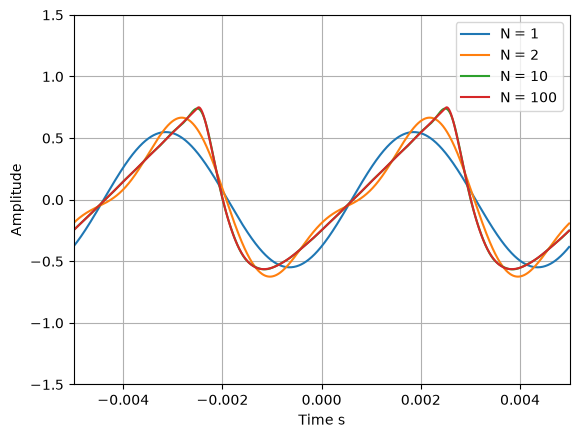

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# From 1b)
dt = 0.00001
t = np.arange(-0.005, 0.005, dt)
w = (2*np.pi) / 0.005

# Input X(w)
M = 100
n = np.arange( -M, M + 1, 1)
w = (2*np.pi)/0.005

wn = n * w
Xn = 2 * np.pi * ((-1.0)**n) * 1j * (1 /(n * np.pi))
Xn[n == 0] = 0

# Frequency Response 
alpha = 1000 * np.pi
H = (alpha**2)/((alpha+1j*wn)**2)
Yn = H*Xn

fig, ax = plt.subplots()

N_val = [1, 2, 10, 100]
for N in N_val:
    n = np.arange(-N, N + 1)
    fs = 0

    for i in n:
        fs += Yn[M + i] * np.exp(1j * i * w * t)

    if np.max(np.abs(np.imag(fs))) < 1e-12:
        fs = np.real(fs)

    fs = fs * 1/(2*np.pi)
    ax.plot(t, fs, label=f'N = {N}')


ax.set_xlabel('Time s')
ax.set_ylabel('Amplitude')
ax.set_xlim(-0.005, 0.005)
ax.set_ylim(-1.5 , 1.5)

ax.legend()
ax.grid()

plt.show()


As mentioned previously, the system acts as a low-pass filter, meaning it removes the high-frequency components needed to form sharp corners, resulting in a smooth, rounded waveform. Therefore, this plot of the Fourier series for y(t) is much smoother than the sawtooth wave observed in Task 1, and it also has a lower peak amplitude and a slight time delay (phase shift). 

Similar to Task 1b, increasing N from 1 to 10 makes the waveform more frequencies are added. However, unlike Task 1b, where higher values of N continuously sharpened the edges of x(t), the output y(t) stops changing after N = 10, so N = 10 and N = 100 overlap. This is because those higher frequencies have already been filtered out. 